# Share B data checks

**Owner:** Wenyue. Reads the frozen team splits without resplitting or changing labels.

Install `requirements.txt` and `notebooks/requirements-b.txt`, then run `python -m levellens.data.prepare` once. Run all cells. Aggregate evidence is public; sampled question text remains under ignored `data/review/`. The sample observations are preliminary, and Wenyue's item-by-item confirmation is still pending. See `docs/datasets.md` and `docs/audit.md`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
from levellens.paths import REPO_ROOT, results_dir
from levellens.data import load_frame
sys.path.insert(0, str(REPO_ROOT / "notebooks"))
from data_checks import main, DATASETS, SPLITS
summary = main([])
assert not summary["problems"]

race {'train': 100568, 'dev': 5599, 'test': 5642} checked
arc {'train': 3358, 'dev': 862, 'test': 3530} checked


math {'train': 6748, 'dev': 750, 'test': 5000} checked
scienceqa {'train': 6508, 'dev': 2144, 'test': 2224} checked
Aggregate evidence saved. Raw review text remains in the configured data directory.


## Counts, shape and missing values

`validate` rejects missing required fields and blank inputs before any statistics are computed. A null passage is expected outside RACE++. The frozen manifest hashes IDs, levels and prepared input text. Derived subsets are checked against their parent and are excluded from cross-split leakage counts.

In [2]:
counts = []
for name, dataset in summary["datasets"].items():
    for split, row in dataset["splits"].items():
        counts.append({"dataset": name, "split": split, "rows": row["n"], "columns": row["shape"][1], "counts_match": row["count_matches_design"], "fingerprint_match": row["matches_manifest"], "null_passages": row["nulls"].get("passage", 0)})
display(pd.DataFrame(counts))
# Demonstrate the shared DataFrame loader without publishing raw questions.
arc_train = load_frame("arc", "train")
assert arc_train.shape == (3358, 10)
assert arc_train[["id", "question", "text", "level"]].isna().sum().sum() == 0
del arc_train

,dataset,split,rows,columns,counts_match,fingerprint_match,null_passages
0,race,train,100568,10,True,True,0
1,race,dev,5599,10,True,True,0
2,race,test,5642,10,True,True,0
3,arc,train,3358,10,True,True,3358
4,arc,dev,862,10,True,True,862
5,arc,test,3530,10,True,True,3530
6,math,train,6748,10,True,True,6748
7,math,dev,750,10,True,True,750
8,math,test,5000,10,True,True,5000
9,scienceqa,train,6508,10,True,True,6508


## Class balance

Each plot shows the fraction within each split, with its denominator in the legend. These are data-check statistics, not model performance.

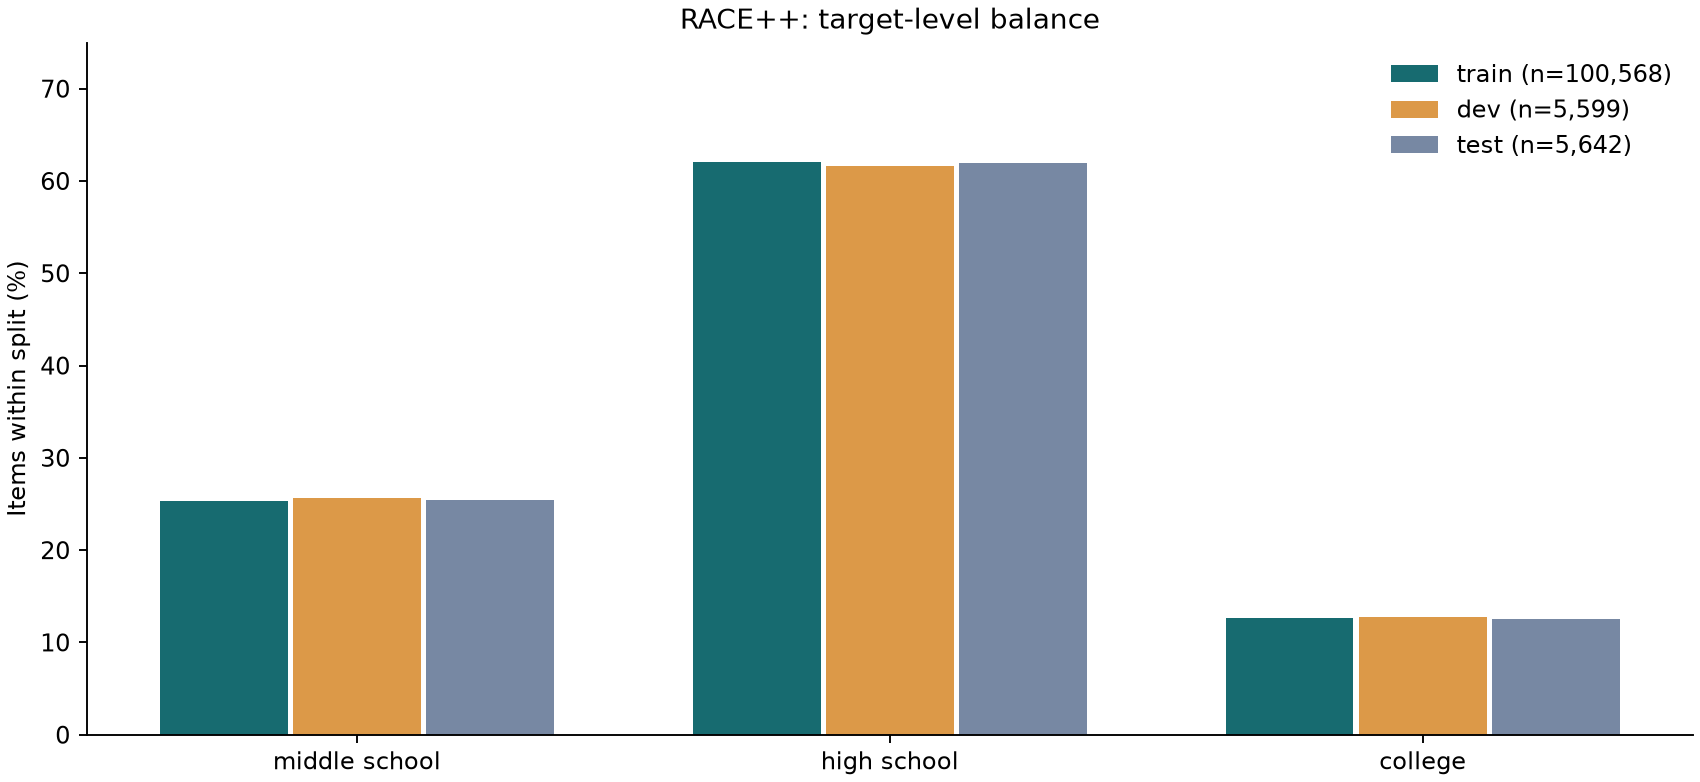

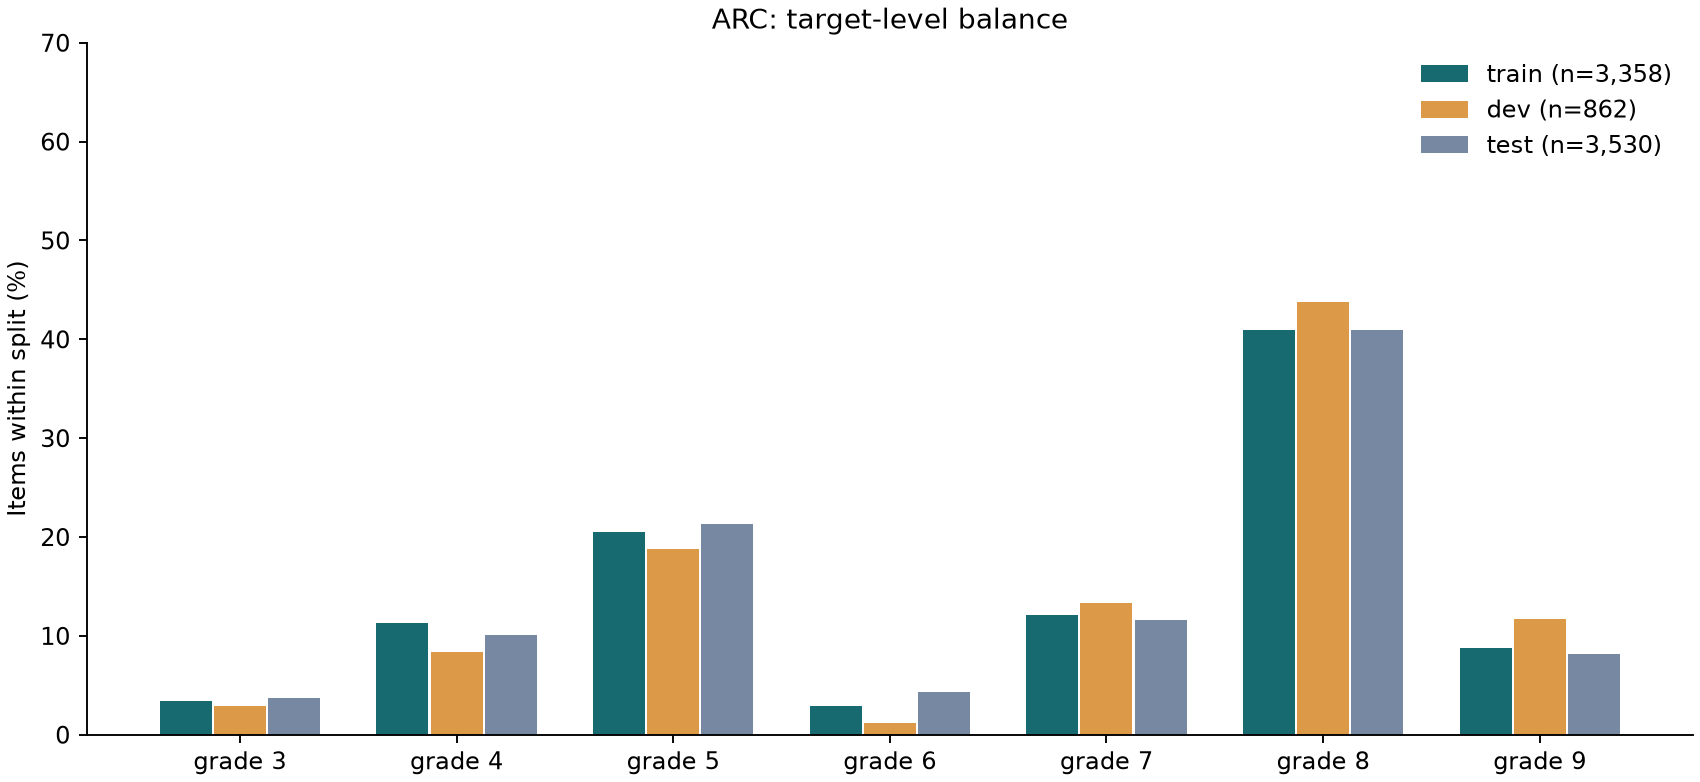

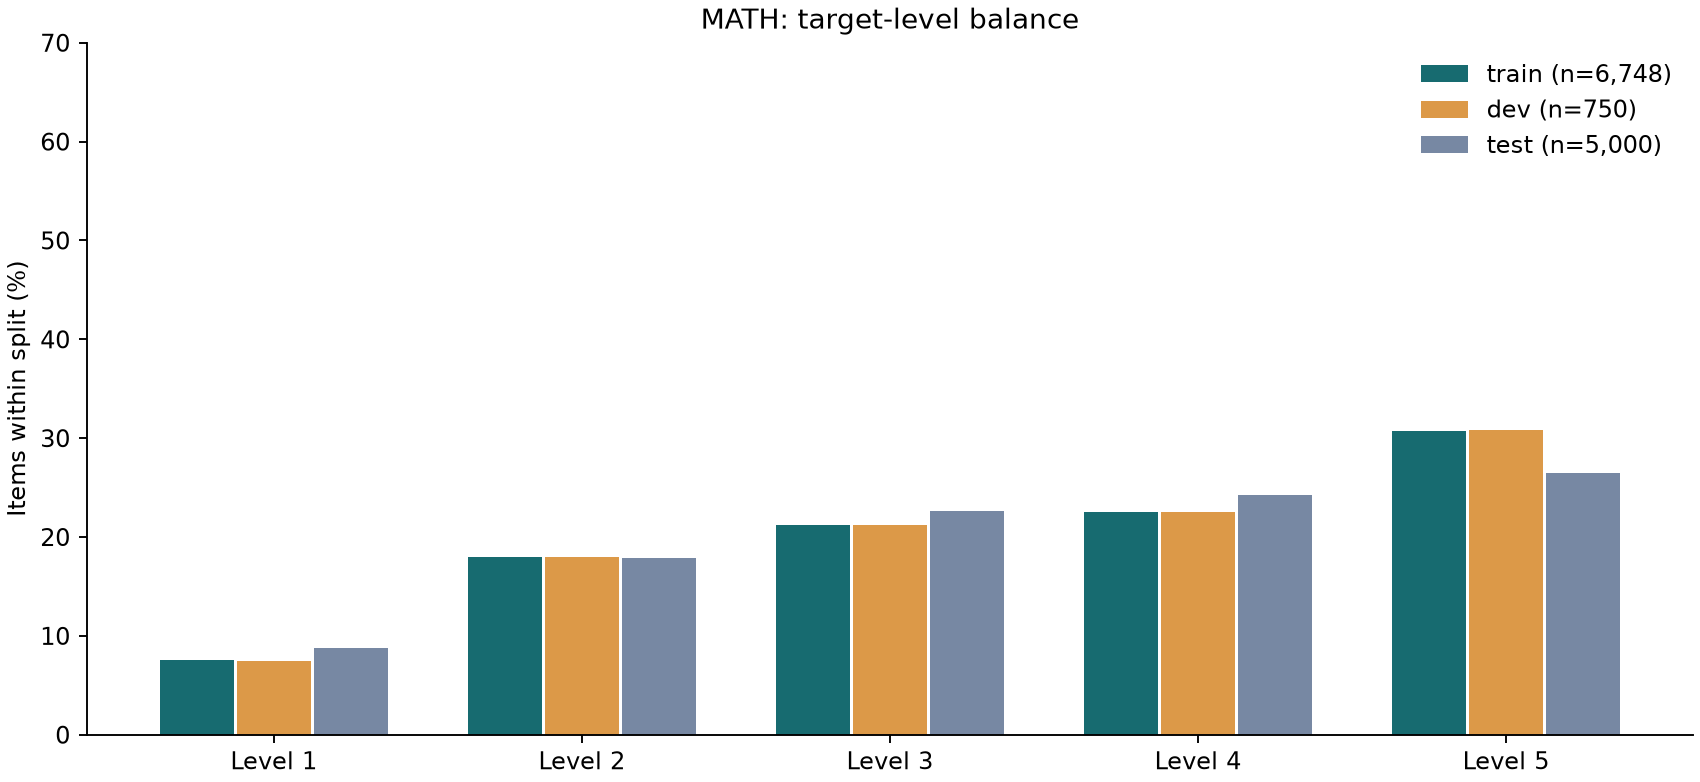

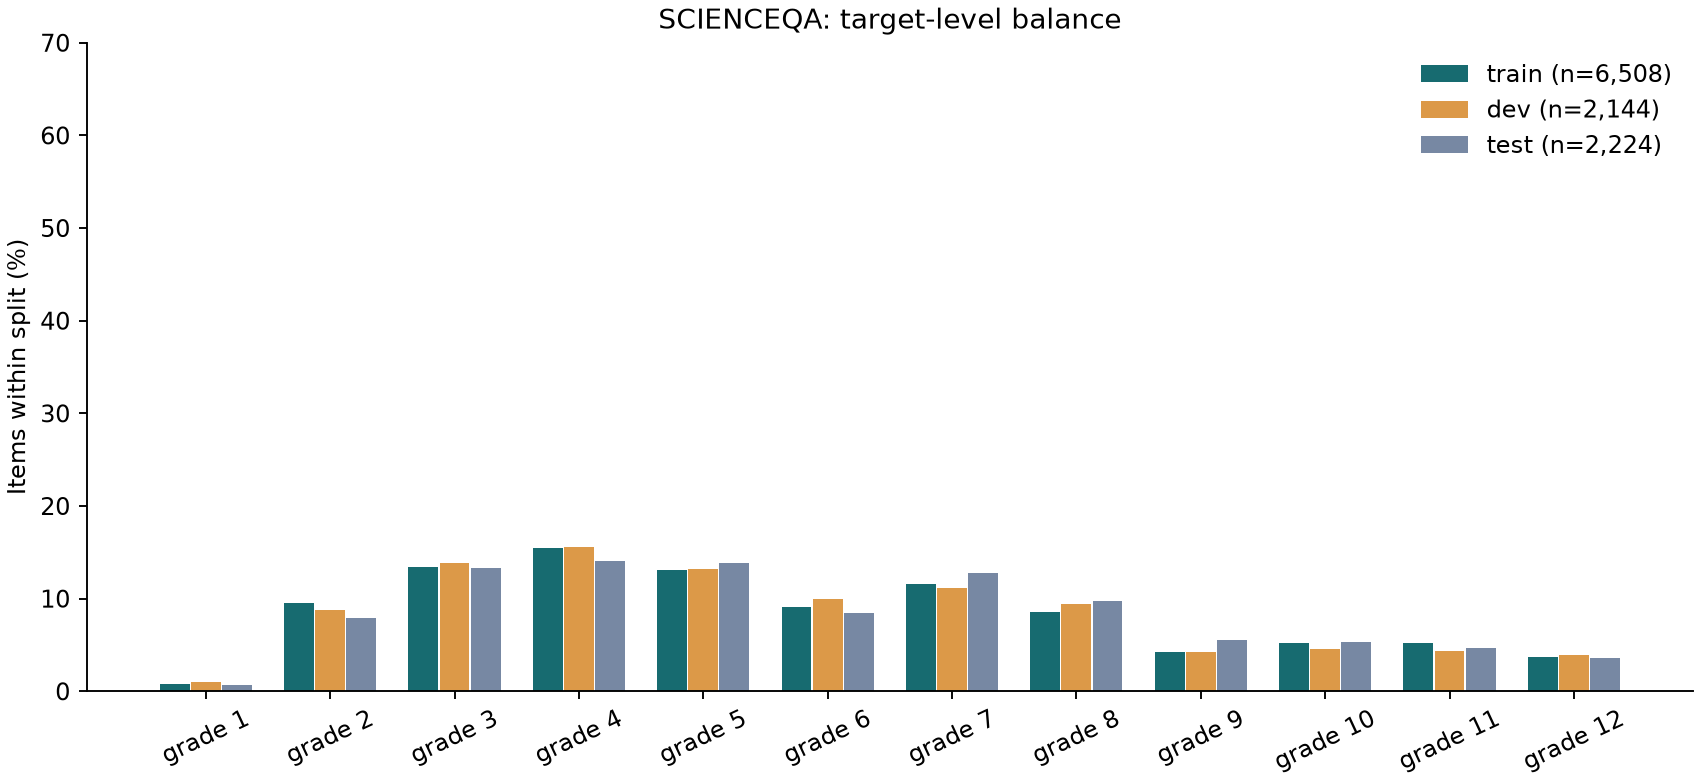

In [3]:
for name in DATASETS:
    display(Image(filename=str(results_dir() / "data_checks" / f"{name}_balance.png")))

## Exact repeats

`question` means exact stored stem strings. `text` means exact prepared model inputs; the adapter has already normalised whitespace. A repeated stem is not necessarily a repeated contextual question. Shared strings, affected rows and matching pairs are different units. Near-duplicate search is outside the reduced B1 scope.

In [4]:
duplicates = []
for name, dataset in summary["datasets"].items():
    for field, values in dataset["duplicates"].items():
        for pair, row in values["across"].items():
            duplicates.append({"dataset": name, "field": field, "split_pair": pair, **row})
display(pd.DataFrame(duplicates))

,dataset,field,split_pair,groups,rows_left,rows_right,pairs,conflicting_level_groups
0,race,question,train:dev,773,10672,1180,61427,352
1,race,question,train:test,729,11001,1190,67482,356
2,race,question,dev:test,221,593,633,3439,110
3,race,text,train:dev,146,154,146,154,100
4,race,text,train:test,156,169,156,169,96
5,race,text,dev:test,11,11,11,11,9
6,arc,question,train:dev,2,2,2,2,1
7,arc,question,train:test,15,16,16,17,3
8,arc,question,dev:test,2,2,2,2,1
9,arc,text,train:dev,0,0,0,0,0


## Length by level and split

A word is a whitespace-delimited token, not a model-tokeniser token. LaTeX and Asymptote code are counted as literal text. All three primary splits and both question-only and full-input lengths are retained in `summary.json`.

In [5]:
lengths = []
for name, dataset in summary["datasets"].items():
    for split, values in dataset["splits"].items():
        for row in values["lengths"]:
            lengths.append({"dataset":name,"split":split,"level":dataset["level_names"][row["level"]],"n":row["n"],"question_mean_words":row["question_words"]["mean"],"input_median_words":row["text_words"]["median"],"input_p95_words":row["text_words"]["p95"]})
display(pd.DataFrame(lengths))

,dataset,split,level,n,question_mean_words,input_median_words,input_p95_words
0,race,train,middle school,25421,9.05,29.0,53.0
1,race,train,high school,62445,10.40,39.0,60.0
2,race,train,college,12702,11.81,42.0,72.0
3,race,dev,middle school,1436,8.94,28.0,53.0
4,race,dev,high school,3451,10.24,39.0,59.0
...,...,...,...,...,...,...,...
76,scienceqa,test,grade 8,217,17.35,31.0,64.2
77,scienceqa,test,grade 9,122,21.17,34.5,74.0
78,scienceqa,test,grade 10,119,23.17,39.0,82.2
79,scienceqa,test,grade 11,105,28.83,41.0,94.4


## Published-majority sanity checks

Use the repository's `Majority`, including its highest-level tie rule. These arithmetic checks are not final-model experiments. Grade 8 wins for both ARC training variants, so matching this row cannot prove matching training IDs.

In [6]:
from levellens.models.floors import Majority
from levellens.data import info, load_split
from levellens.evaluate import evaluate
import numpy as np
import json
majority_rows = []
expected = {"race": [0.620, 0.616, 0.667], "arc": [0.409, 2.195, 2.286]}
for name, train_split in [("race", "train"), ("arc", "train_balanced")]:
    train = load_split(name, train_split)
    test = load_split(name, "test")
    model = Majority(info(name).num_levels)
    model.fit(train, [], None)
    metrics = evaluate(np.array([r["level"] for r in test]), model.predict_proba(test), info(name).num_levels)
    selected = {k: metrics[k] for k in ["accuracy", "rmse", "balanced_drps"]}
    assert [round(v, 3) for v in selected.values()] == expected[name]
    majority_rows.append({"dataset": name, "train_split": train_split, "predicted_level": model.level_, "metrics": selected})
(results_dir() / "data_checks" / "majority_check.json").write_text(json.dumps(majority_rows, indent=2) + "\n", encoding="utf-8")
display(pd.DataFrame([{**r["metrics"], "dataset": r["dataset"], "train_split": r["train_split"]} for r in majority_rows]))

,accuracy,rmse,balanced_drps,dataset,train_split
0,0.619993,0.616447,0.666667,race,train
1,0.409065,2.194572,2.285714,arc,train_balanced


## Sample reading and follow-up

Ten training examples per level are selected by a stable SHA-256 rank with sample seed 38. This produces 270 examples. Their complete questions, available passages, options and metadata stay in `data/review/*_10_per_level.jsonl`. Qualitative observations and exact sample IDs appear in `docs/datasets.md` and `results/data_checks/sample_review.json`. Sampling does not validate every label or estimate a label-error rate. Final-model error adjudication needs F's 15-case handoff and is still pending.

In [7]:
display(pd.DataFrame([{"dataset":name,"per_level":row["review_sample_per_level"],"total":sum(row["review_sample_per_level"])} for name,row in summary["datasets"].items()]))
assert sum(sum(row["review_sample_per_level"]) for row in summary["datasets"].values()) == 270

,dataset,per_level,total
0,race,"[10, 10, 10]",30
1,arc,"[10, 10, 10, 10, 10, 10, 10]",70
2,math,"[10, 10, 10, 10, 10]",50
3,scienceqa,"[10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]",120
